## 03 Figures
Charts for README. Numbers come from same weighted tables as 02_analysis

## 1. Setup

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.helpers import weighted_ci, table_by

df = pd.read_csv("../data/processed/clean.csv").copy()
print(df.shape)

(1103, 348)


## 2. Figure A: It's the job, not the age
Weighted % using AI at work, by age and by job type (95% CI).

In [2]:
fig_age = table_by(df, "age_group", "ai_work", ["18-29", "30-44", "45-59", "60+"])
print(fig_age, "\n")

fig_job = table_by(df, "job_broad", "ai_work", ["Office/knowledge", "Care & education", "Frontline"])
print(fig_job)

            pct  ci_lo  ci_hi    n note
age_group                              
18-29      42.0   35.6   48.4  232     
30-44      49.1   44.1   54.1  381     
45-59      41.2   35.7   46.7  312     
60+        32.3   25.4   39.2  177      

                   pct  ci_lo  ci_hi    n note
job_broad                                     
Office/knowledge  57.3   52.6   61.9  432     
Care & education  41.4   34.4   48.3  196     
Frontline         31.0   26.2   35.9  354     


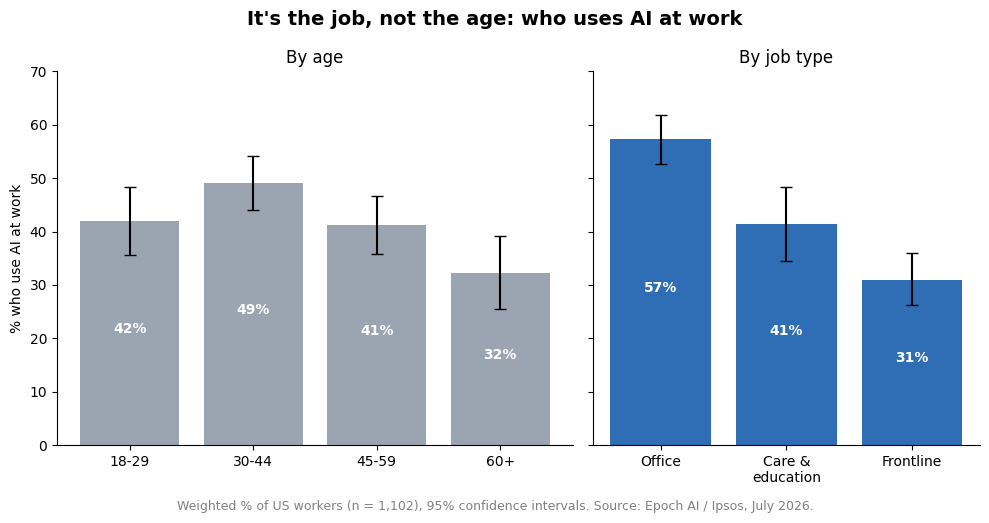

In [3]:
# Two panels side by side; shared y-axis; age panel a bit wider (4 bars vs 3)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True,
                               gridspec_kw={"width_ratios": [4, 3]})

# Left panel: by age
err_age = [fig_age["pct"] - fig_age["ci_lo"], fig_age["ci_hi"] - fig_age["pct"]]
ax1.bar(fig_age.index, fig_age["pct"], yerr=err_age, capsize=4, color="#9aa5b1")
ax1.set_title("By age")
ax1.set_ylabel("% who use AI at work")

# Right panel: by job type (shorter labels so they fit)
job_labels = ["Office", "Care &\neducation", "Frontline"]
err_job = [fig_job["pct"] - fig_job["ci_lo"], fig_job["ci_hi"] - fig_job["pct"]]
ax2.bar(job_labels, fig_job["pct"], yerr=err_job, capsize=4, color="#2f6db5")
ax2.set_title("By job type")

# % labels inside each bar + remove top/right border lines (cleaner look)
for ax, t in [(ax1, fig_age), (ax2, fig_job)]:
    for i, v in enumerate(t["pct"]):
        ax.text(i, v / 2, f"{v:.0f}%", ha="center", color="white", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

ax1.set_ylim(0, 70)
fig.suptitle("It's the job, not the age: who uses AI at work", fontsize=14, fontweight="bold")
fig.text(0.5, -0.02,
         "Weighted % of US workers (n = 1,102), 95% confidence intervals. "
         "Source: Epoch AI / Ipsos, July 2026.",
         ha="center", fontsize=9, color="gray")
fig.tight_layout()

fig.savefig("../figures/fig1_job_not_age.png", dpi=200, bbox_inches="tight")
plt.show()